<a href="https://colab.research.google.com/github/achintya-maurya/UCS-420/blob/main/Copy_of_UCS420_LA9_Starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [17]:
ROLL_NO = 1024170429       # <-- your full roll number
NAME = "Achintya Maurya"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [20]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [15]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [16]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170429   Name: Achintya Maurya   Fingerprint: D11D4ACA   Tickets: 16

Ticket_ID                                                                                  Ticket_Text
      T01                           I can't open the VPN while uploading the file. Can you check this?
      T02                                The projector is showing an error. I don't know what changed.
      T03                                                         Email me at helpdesk@university.edu.
      T04                            The password was working yesterday. It works on another computer.
      T05                                 LMS crashes while opening on my laptop. It worked yesterday.
      T06                                                  The state-of-the-art lab (Lab-3) is closed.
      T07                    I am unable to use the Matlab after the latest update. Please resolve it.
      T08                                                        The Wi-Fi works, but the

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [21]:
# Your code

# Q1. Preprocessing pipeline

import pandas as pd

rows = []
all_results = {}

# Process every ticket
for _, row in df.iterrows():
    ticket_id = row["Ticket_ID"]
    ticket_text = row["Ticket_Text"]

    result = process_ticket(ticket_text)
    all_results[ticket_id] = result

    rows.append({
        "Ticket_ID": ticket_id,
        "Sentences": len(result["sentences"]),
        "Tokens": len(result["tokens"]),
        "Punctuation Tokens": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique Tokens": len(set(result["tokens"])),
        "Final Tokens": len(result["final"])
    })

# Create summary table
summary = pd.DataFrame(rows)

# Add TOTAL row for count-based columns
total_row = {
    "Ticket_ID": "TOTAL",
    "Sentences": summary["Sentences"].sum(),
    "Tokens": summary["Tokens"].sum(),
    "Punctuation Tokens": summary["Punctuation Tokens"].sum(),
    "Stopwords": summary["Stopwords"].sum(),
    "Unique Tokens": "-",
    "Final Tokens": summary["Final Tokens"].sum()
}

summary = pd.concat(
    [summary, pd.DataFrame([total_row])],
    ignore_index=True
)

print("Q1: PREPROCESSING SUMMARY")
display(summary)

# Display actual tokens for one selected ticket
selected_ticket = "T01"
selected_result = all_results[selected_ticket]

print(f"\nDetailed preprocessing for {selected_ticket}")
print("Actual tokens:", selected_result["tokens"])
print("Punctuation tokens:", selected_result["punct"])
print("Stopwords:", selected_result["stops"])
print("Final tokens:", selected_result["final"])


Q1: PREPROCESSING SUMMARY


,Ticket_ID,Sentences,Tokens,Punctuation Tokens,Stopwords,Unique Tokens,Final Tokens
0,T01,2,16,2,7,15,7
1,T02,2,14,2,6,13,6
2,T03,1,7,2,2,7,3
3,T04,2,12,2,4,11,6
4,T05,2,12,2,4,11,6
5,T06,1,9,3,2,9,4
6,T07,2,16,2,7,14,7
7,T08,1,10,2,4,9,4
8,T09,2,19,2,9,16,8
9,T10,2,19,2,8,17,9



Detailed preprocessing for T01
Actual tokens: ['i', 'ca', "n't", 'open', 'the', 'vpn', 'while', 'uploading', 'the', 'file', '.', 'can', 'you', 'check', 'this', '?']
Punctuation tokens: ['.', '?']
Stopwords: ['i', 'the', 'while', 'the', 'can', 'you', 'this']
Final tokens: ['ca', "n't", 'open', 'vpn', 'uploading', 'file', 'check']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*

Answer: In my dataset, the final tokens include `ca` and `n't`, which are not complete words. They come from the contraction “can't”. The tokenizer splits the contraction into separate tokens. Since the preprocessing pipeline removes punctuation tokens and stopwords but does not join contraction parts, these incomplete tokens remain in the final output.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [33]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

import re
import pandas as pd

# Q2: REGEX PATTERNS
long_word_pattern = r"\b[A-Za-z]{6,}\b"

# Match comma-formatted numbers first, then decimals and integers
number_pattern = r"(?<![\w.])(?:\d{1,3}(?:,\d{3})+|\d+)(?:\.\d+)*(?![\w.])"

capitalized_pattern = r"\b[A-Z][a-zA-Z]*\b"
vowel_pattern = r"\b[aeiouAEIOU][a-zA-Z]*\b"

email_pattern = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"
url_pattern = r"(?:https?://|www\.)[^\s;,]+"

phone_pattern = (
    r"(?<!\w)"
    r"(?:\+91[\s-]?)?"
    r"(?:\d{5}[\s-]?\d{5}|\d{4}[\s-]\d{3}[\s-]\d{4})"
    r"(?!\w)"
)

def extract_matches(text, pattern):
    return re.findall(pattern, str(text))

def extract_numbers_excluding_phones(text):
    text = str(text)
    phone_matches = list(re.finditer(phone_pattern, text))
    numbers = []

    for match in re.finditer(number_pattern, text):
        # Ignore numeric matches located inside phone numbers
        if any(
            match.start() < phone.end() and match.end() > phone.start()
            for phone in phone_matches
        ):
            continue
        numbers.append(match.group())

    return numbers

def clean_sensitive_info(text):
    text = re.sub(email_pattern, "<EMAIL>", str(text))
    text = re.sub(url_pattern, "<URL>", text)
    text = re.sub(phone_pattern, "<PHONE>", text)
    return text

text_column = "Ticket_Text"

if text_column not in df.columns:
    raise ValueError(f"Column '{text_column}' not found in dataset.")

ticket_texts = df[text_column].dropna().astype(str).tolist()
test_lines = list(TEST_LINES)

all_texts = ticket_texts + test_lines
labels = (
    [f"Ticket_{i+1}" for i in range(len(ticket_texts))]
    + [f"TEST_LINE_{i+1}" for i in range(len(test_lines))]
)

results = []

for label, text in zip(labels, all_texts):
    results.append({
        "Source": label,
        "Long Words": extract_matches(text, long_word_pattern),
        "Numbers": extract_numbers_excluding_phones(text),
        "Capitalized Words": extract_matches(text, capitalized_pattern),
        "Vowel-starting Words": extract_matches(text, vowel_pattern),
        "Emails": extract_matches(text, email_pattern),
        "URLs": extract_matches(text, url_pattern),
        "Phone Numbers": extract_matches(text, phone_pattern)
    })

results_df = pd.DataFrame(results)

print("Ticket text column used:", text_column)
display(results_df)

print("\nREPLACED TEST LINES")
for i, line in enumerate(test_lines, start=1):
    print(f"TEST_LINE_{i}: {clean_sensitive_info(line)}")

print("\nREPLACED RAW TICKETS")
for i, ticket in enumerate(ticket_texts, start=1):
    print(f"Ticket_{i}: {clean_sensitive_info(ticket)}")

print("\nNUMBER EXTRACTION CHECK:")
print(extract_numbers_excluding_phones(test_lines[1]))





Ticket text column used: Ticket_Text


,Source,Long Words,Numbers,Capitalized Words,Vowel-starting Words,Emails,URLs,Phone Numbers
0,Ticket_1,[uploading],[],"[I, VPN, Can]","[I, open, uploading]",[],[],[]
1,Ticket_2,"[projector, showing, changed]",[],"[The, I]","[is, an, error, I]",[],[],[]
2,Ticket_3,"[helpdesk, university]",[],[Email],"[Email, at, university, edu]",[helpdesk@university.edu],[],[]
3,Ticket_4,"[password, working, yesterday, another, computer]",[],"[The, It]","[It, on, another]",[],[],[]
4,Ticket_5,"[crashes, opening, laptop, worked, yesterday]",[],"[LMS, It]","[opening, on, It]",[],[],[]
5,Ticket_6,[closed],[3],"[The, Lab]","[of, art, is]",[],[],[]
6,Ticket_7,"[unable, Matlab, latest, update, Please, resolve]",[],"[I, Matlab, Please]","[I, am, unable, use, after, update, it]",[],[],[]
7,Ticket_8,[],[],"[The, Wi, Fi, VPN]",[],[],[],[]
8,Ticket_9,"[getting, logged, printer, during, changed]",[],"[I, I]","[I, out, of, I]",[],[],[]
9,Ticket_10,"[unable, projector, connected, campus, several]",[],"[I, Wi, Fi, I]","[I, am, unable, use, I]",[],[],[]



REPLACED TEST LINES
TEST_LINE_1: Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>
TEST_LINE_2: Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.
TEST_LINE_3: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.

REPLACED RAW TICKETS
Ticket_1: I can't open the VPN while uploading the file. Can you check this?
Ticket_2: The projector is showing an error. I don't know what changed.
Ticket_3: Email me at <EMAIL>.
Ticket_4: The password was working yesterday. It works on another computer.
Ticket_5: LMS crashes while opening on my laptop. It worked yesterday.
Ticket_6: The state-of-the-art lab (Lab-3) is closed.
Ticket_7: I am unable to use the Matlab after the latest update. Please resolve it.
Ticket_8: The Wi-Fi works, but the VPN doesn't.
Ticket_9: I keep getting logged out of the printer during the lab. I don't know what changed.
Ticket_10: I am unable to use the projector when connected to campus Wi-Fi. I have tried several times!
Ticket_11: I c

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*
Some capitalized words are capitalized only because they appear at the beginning of a sentence, such as “The”, “I”, “It”, and “Please”. Other words, such as “VPN”, “LMS”, “Wi”, “Fi”, and “Matlab”, are capitalized because they are abbreviations, technical terms, or product names. Therefore, not all capitalized words represent proper nouns.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [34]:
# Your code

import re
import pandas as pd
from nltk.tokenize import word_tokenize, RegexpTokenizer

# Custom tokenizer pattern
token_pattern = (
    r"https?://[^\s;,]+|www\.[^\s;,]+|"                  # URLs
    r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|"  # Emails
    r"(?:\+91[\s-]?)?(?:\d{5}[\s-]?\d{5}|\d{4}[\s-]\d{3}[\s-]\d{4})|"  # Phones
    r"\d+(?:\.\d+)+|"                                    # Decimals and versions
    r"[A-Za-z]+(?:[-'][A-Za-z]+)+|"                      # Hyphenated words and contractions
    r"[A-Za-z]+|"                                        # Ordinary words
    r"\d+(?:,\d{3})*(?:\.\d+)?|"                         # Numbers
    r"[^\w\s]"                                           # Remaining punctuation
)

custom_tokenizer = RegexpTokenizer(token_pattern)

def my_tokenize(text):
    return custom_tokenizer.tokenize(str(text))

# Compare custom tokenizer with word_tokenize
print("TEST LINES COMPARISON\n")

for i, line in enumerate(TEST_LINES, start=1):
    custom_tokens = my_tokenize(line)
    standard_tokens = word_tokenize(line)

    print(f"TEST_LINE_{i}")
    print("Custom tokenizer:", custom_tokens)
    print("word_tokenize:   ", standard_tokens)
    print()

# Compare on all tickets
print("TICKET COMPARISON\n")

comparison_results = []

for i, text in enumerate(df["Ticket_Text"].dropna().astype(str), start=1):
    custom_tokens = my_tokenize(text)
    standard_tokens = word_tokenize(text)

    comparison_results.append({
        "Ticket": f"Ticket_{i}",
        "Custom Token Count": len(custom_tokens),
        "word_tokenize Count": len(standard_tokens),
        "Different?": custom_tokens != standard_tokens,
        "Custom Tokens": custom_tokens,
        "word_tokenize Tokens": standard_tokens
    })

comparison_df = pd.DataFrame(comparison_results)
display(comparison_df)

different_count = comparison_df["Different?"].sum()

print(
    f"\nObservation: {different_count} out of "
    f"{len(comparison_df)} tickets are tokenized differently "
    "by my_tokenize and word_tokenize."
)


TEST LINES COMPARISON

TEST_LINE_1
Custom tokenizer: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize:    ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

TEST_LINE_2
Custom tokenizer: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
word_tokenize:    ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

TEST_LINE_3
Custom tokenizer: ['The', 'state-of-the-art', 'lab', "isn't", 'open', ';', 'log-in', 'at', '5.30', 'p', '.', 'm', '.', "didn't", 'work', '.']
word_tokenize:    ['The', 'state-of-the-art', 'lab', 'is', "n't", 'open', ';', 'log-in', 'at', 

,Ticket,Custom Token Count,word_tokenize Count,Different?,Custom Tokens,word_tokenize Tokens
0,Ticket_1,15,16,True,"[I, can't, open, the, VPN, while, uploading, t...","[I, ca, n't, open, the, VPN, while, uploading,..."
1,Ticket_2,13,14,True,"[The, projector, is, showing, an, error, ., I,...","[The, projector, is, showing, an, error, ., I,..."
2,Ticket_3,5,7,True,"[Email, me, at, helpdesk@university.edu, .]","[Email, me, at, helpdesk, @, university.edu, .]"
3,Ticket_4,12,12,False,"[The, password, was, working, yesterday, ., It...","[The, password, was, working, yesterday, ., It..."
4,Ticket_5,12,12,False,"[LMS, crashes, while, opening, on, my, laptop,...","[LMS, crashes, while, opening, on, my, laptop,..."
5,Ticket_6,11,9,True,"[The, state-of-the-art, lab, (, Lab, -, 3, ), ...","[The, state-of-the-art, lab, (, Lab-3, ), is, ..."
6,Ticket_7,16,16,False,"[I, am, unable, to, use, the, Matlab, after, t...","[I, am, unable, to, use, the, Matlab, after, t..."
7,Ticket_8,9,10,True,"[The, Wi-Fi, works, ,, but, the, VPN, doesn't, .]","[The, Wi-Fi, works, ,, but, the, VPN, does, n'..."
8,Ticket_9,18,19,True,"[I, keep, getting, logged, out, of, the, print...","[I, keep, getting, logged, out, of, the, print..."
9,Ticket_10,19,19,False,"[I, am, unable, to, use, the, projector, when,...","[I, am, unable, to, use, the, projector, when,..."



Observation: 8 out of 16 tickets are tokenized differently by my_tokenize and word_tokenize.


**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*
**Observation:** Out of 16 tickets, 8 tickets are tokenized differently by `my_tokenize()` and `word_tokenize()`. The custom tokenizer keeps contractions such as “can't” and “doesn't”, email addresses, and hyphenated words such as “state-of-the-art” and “Wi-Fi” together as single tokens. In comparison, `word_tokenize()` splits some contractions and email addresses into multiple tokens. Both tokenizers produce the same tokens for the remaining 8 tickets.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [37]:
# Your code

import re
import nltk
import pandas as pd
from collections import Counter, defaultdict
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk import pos_tag
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer

# Download required NLTK resources
for resource in [
    "punkt",
    "punkt_tab",
    "averaged_perceptron_tagger",
    "averaged_perceptron_tagger_eng",
    "stopwords",
    "wordnet",
    "omw-1.4"
]:
    nltk.download(resource, quiet=True)

# --------------------------------------------------
# Q4: STEMMING AND LEMMATIZATION
# Use only the actual generated ticket dataset
# --------------------------------------------------

if "df" not in globals() or "Ticket_Text" not in df.columns:
    raise ValueError("Run the dataset-generation cells first. Ticket_Text column is required.")

ticket_texts = df["Ticket_Text"].dropna().astype(str).tolist()

stop_words = set(stopwords.words("english"))
punctuation_pattern = re.compile(r"^[^\w]+$")

# Get final tokens from Q1 if available; otherwise
# reproduce lowercase, punctuation and stopword removal.
candidate_names = [
    "final_tokens_by_ticket",
    "ticket_final_tokens",
    "all_final_tokens",
    "unique_final_tokens",
    "final_unique_tokens",
    "final_tokens"
]

source_tokens = None

for name in candidate_names:
    if name not in globals():
        continue

    value = globals()[name]

    if isinstance(value, pd.DataFrame):
        possible_columns = [
            c for c in value.columns
            if "final" in str(c).lower() and "token" in str(c).lower()
        ]
        if possible_columns:
            value = value[possible_columns[0]].dropna().tolist()

    if isinstance(value, (list, tuple, set, pd.Series)):
        # Flatten a list of token lists, if necessary
        flattened = []
        for item in value:
            if isinstance(item, (list, tuple, set)):
                flattened.extend(item)
            else:
                flattened.append(item)

        if flattened and all(isinstance(x, str) for x in flattened):
            source_tokens = flattened
            print("Using Q1 tokens from:", name)
            break

# Fallback: reproduce the Q1 final-token filtering on tickets only
if source_tokens is None:
    source_tokens = []

    for text in ticket_texts:
        tokens = word_tokenize(text.lower())

        for token in tokens:
            if punctuation_pattern.fullmatch(token):
                continue
            if token in stop_words:
                continue
            source_tokens.append(token)

    print("Recreated final tokens from Ticket_Text using lowercase, punctuation and stopword removal.")

# Unique alphabetic final tokens
unique_words = sorted({
    token.lower()
    for token in source_tokens
    if isinstance(token, str)
    and re.fullmatch(r"[a-zA-Z]+", token)
})

if not unique_words:
    raise ValueError("No alphabetic final tokens found. Check the Q1 final-token variable.")

# --------------------------------------------------
# POS tagging with sentence context from the tickets
# --------------------------------------------------

pos_counts = defaultdict(Counter)

for text in ticket_texts:
    tokens = word_tokenize(text.lower())
    tagged_sequence = pos_tag(tokens)

    for word, tag in tagged_sequence:
        if word in unique_words:
            pos_counts[word][tag] += 1

def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return "a"
    if tag.startswith("V"):
        return "v"
    if tag.startswith("N"):
        return "n"
    if tag.startswith("R"):
        return "r"
    return "n"

# Initialize methods
porter = PorterStemmer()
lancaster = LancasterStemmer()

# Dataset-based suffix rule:
# uploading, working, syncing -> remove "ing"
# changed, stopped, logged -> remove "ed"
# crashes, times -> remove "s"
regex_stemmer = RegexpStemmer(
    r"(ing|ed|es|s)$",
    min=4
)

lemmatizer = WordNetLemmatizer()

results = []

for word in unique_words:
    # Select the most frequent contextual POS tag.
    # If the word was not found in ticket context, use noun.
    if pos_counts[word]:
        tag = pos_counts[word].most_common(1)[0][0]
    else:
        tag = "NN"

    wordnet_pos = get_wordnet_pos(tag)

    results.append({
        "Word": word,
        "POS Tag": tag,
        "Porter Stem": porter.stem(word),
        "Lancaster Stem": lancaster.stem(word),
        "Regex Stem": regex_stemmer.stem(word),
        "WordNet Lemma": lemmatizer.lemmatize(word, pos=wordnet_pos)
    })

comparison_df = pd.DataFrame(results)

method_columns = [
    "Porter Stem",
    "Lancaster Stem",
    "Regex Stem",
    "WordNet Lemma"
]

# Display only words for which the methods disagree
different_words_df = comparison_df[
    comparison_df[method_columns].nunique(axis=1) > 1
].reset_index(drop=True)

print("\nQ4 RESULTS")
print("Number of unique alphabetic final tokens:", len(unique_words))
print("Number of words with differing outputs:", len(different_words_df))

display(different_words_df)

print("\nREGEX STEMMER RULE JUSTIFICATION")
print(
    "The suffix rule removes ing, ed, es or s from suitable words. "
    "It was selected after inspecting dataset words such as uploading, "
    "working, syncing, changed and crashes. This simple rule demonstrates "
    "suffix-based stemming, but may produce imperfect stems for some words."
)

print("\nEXAMPLES")
display(different_words_df.head(10))


Recreated final tokens from Ticket_Text using lowercase, punctuation and stopword removal.

Q4 RESULTS
Number of unique alphabetic final tokens: 52
Number of words with differing outputs: 27


,Word,POS Tag,Porter Stem,Lancaster Stem,Regex Stem,WordNet Lemma
0,another,DT,anoth,anoth,another,another
1,campus,VB,campu,camp,campu,campus
2,changed,VBD,chang,chang,chang,change
3,closed,VBN,close,clos,clos,close
4,computer,NN,comput,comput,computer,computer
5,error,NN,error,er,error,error
6,file,NN,file,fil,file,file
7,getting,VBG,get,get,gett,get
8,latest,JJS,latest,latest,latest,late
9,lms,NNS,lm,lms,lms,lm



REGEX STEMMER RULE JUSTIFICATION
The suffix rule removes ing, ed, es or s from suitable words. It was selected after inspecting dataset words such as uploading, working, syncing, changed and crashes. This simple rule demonstrates suffix-based stemming, but may produce imperfect stems for some words.

EXAMPLES


,Word,POS Tag,Porter Stem,Lancaster Stem,Regex Stem,WordNet Lemma
0,another,DT,anoth,anoth,another,another
1,campus,VB,campu,camp,campu,campus
2,changed,VBD,chang,chang,chang,change
3,closed,VBN,close,clos,clos,close
4,computer,NN,comput,comput,computer,computer
5,error,NN,error,er,error,error
6,file,NN,file,fil,file,file
7,getting,VBG,get,get,gett,get
8,latest,JJS,latest,latest,latest,late
9,lms,NNS,lm,lms,lms,lm


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:
***Over-stemming:** The LancasterStemmer changes “open” to “op”, which removes too much of the original word and makes the stem less meaningful.

**Under-stemming:** The PorterStemmer leaves “asking” as “ask” while WordNetLemmatizer returns “asking” because the POS tag identifies it as a noun (`NN`). In this context, “asking” is a verb form, so the lemmatizer does not reduce it to “ask”.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

S3 recreated using lowercase, punctuation and stopword removal.

CORPUS STATISTICS


,Corpus,Total Tokens,Unique Tokens,TTR
0,S1: All tokens,262,128,0.4885
1,S2: No punctuation,217,118,0.5438
2,S3: Final tokens,132,83,0.6288
3,S4: Porter stemming,132,78,0.5909



TOP 10 WORDS IN S1


,Word,Frequency
0,.,29
1,the,11
2,I,10
3,n't,8
4,The,7
5,is,5
6,open,4
7,It,4
8,works,4
9,on,4



TOP 10 WORDS IN S3


,Word,Frequency
0,n't,8
1,open,4
2,works,4
3,ca,3
4,projector,3
5,another,3
6,computer,3
7,laptop,3
8,lab,3
9,please,3


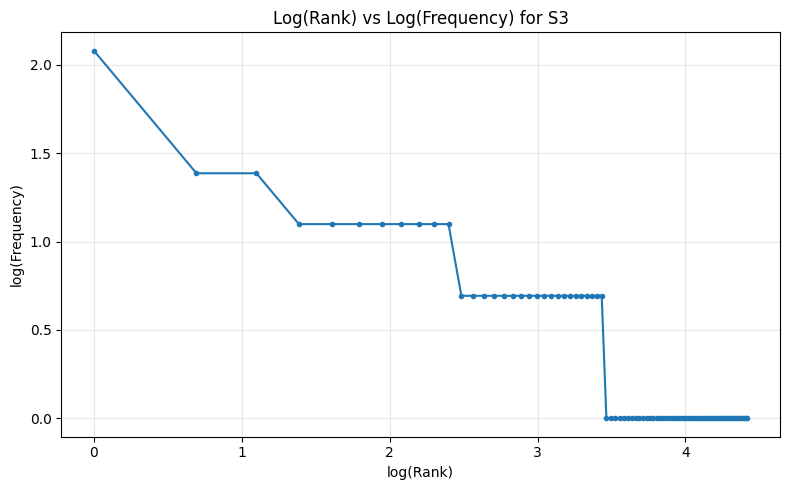


TOP 5 BIGRAMS IN S1


,Bigram,Frequency
0,"(., I)",8
1,"(., The)",5
2,"(n't, open)",4
3,"(., It)",4
4,"(I, ca)",3



TOP 5 BIGRAMS IN S3


,Bigram,Frequency
0,"(n't, open)",4
1,"(ca, n't)",3
2,"(works, another)",3
3,"(another, computer)",3
4,"(n't, know)",2



TTR COMPARISON
S1: All tokens: TTR = 0.4885
S2: No punctuation: TTR = 0.5438
S3: Final tokens: TTR = 0.6288
S4: Porter stemming: TTR = 0.5909


In [36]:
# Your code

import re
import math
import nltk
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter
from nltk.tokenize import word_tokenize
from nltk.util import bigrams
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from string import punctuation

# Required NLTK resources
for resource in ["punkt", "punkt_tab", "stopwords"]:
    nltk.download(resource, quiet=True)

# --------------------------------------------------
# Prepare source text
# --------------------------------------------------
all_texts = (
    df["Ticket_Text"].dropna().astype(str).tolist()
    + list(TEST_LINES)
)

# S1: All tokens, including punctuation
S1 = []
for text in all_texts:
    S1.extend(word_tokenize(text))

# S2: Tokens without punctuation
S2 = [
    token for token in S1
    if any(character.isalnum() for character in token)
]

# S3: Final tokens after preprocessing
# Use previously created final tokens if available.
candidate_names = [
    "final_tokens",
    "unique_final_tokens",
    "final_unique_tokens",
    "tokens_final"
]

S3 = None

for name in candidate_names:
    if name in globals():
        value = globals()[name]
        if isinstance(value, (list, tuple, set, pd.Series)):
            S3 = list(value)
            print("S3 loaded from existing variable:", name)
            break

# If Q1's final-token variable is unavailable, reproduce
# lowercase + punctuation removal + stopword removal.
if S3 is None:
    stop_words = set(stopwords.words("english"))
    S3 = [
        token.lower()
        for token in S1
        if any(char.isalnum() for char in token)
        and token.lower() not in stop_words
    ]
    print("S3 recreated using lowercase, punctuation and stopword removal.")

# S4: S3 after Porter stemming
porter = PorterStemmer()
S4 = [porter.stem(str(token).lower()) for token in S3]

# --------------------------------------------------
# Corpus statistics
# --------------------------------------------------
def corpus_stats(tokens):
    total = len(tokens)
    unique = len(set(tokens))
    ttr = unique / total if total else 0
    return total, unique, ttr

stats = []

for name, tokens in [
    ("S1: All tokens", S1),
    ("S2: No punctuation", S2),
    ("S3: Final tokens", S3),
    ("S4: Porter stemming", S4)
]:
    total, unique, ttr = corpus_stats(tokens)
    stats.append({
        "Corpus": name,
        "Total Tokens": total,
        "Unique Tokens": unique,
        "TTR": round(ttr, 4)
    })

stats_df = pd.DataFrame(stats)

print("\nCORPUS STATISTICS")
display(stats_df)

# --------------------------------------------------
# Top 10 words for S1 and S3
# --------------------------------------------------
print("\nTOP 10 WORDS IN S1")
display(pd.DataFrame(
    Counter(S1).most_common(10),
    columns=["Word", "Frequency"]
))

print("\nTOP 10 WORDS IN S3")
display(pd.DataFrame(
    Counter(S3).most_common(10),
    columns=["Word", "Frequency"]
))

# --------------------------------------------------
# Log(rank) vs log(frequency) for S3
# --------------------------------------------------
frequency_counts = Counter(S3).most_common()
frequencies = [frequency for word, frequency in frequency_counts]

ranks = list(range(1, len(frequencies) + 1))

plt.figure(figsize=(8, 5))
plt.plot(
    [math.log(rank) for rank in ranks],
    [math.log(freq) for freq in frequencies],
    marker="."
)
plt.xlabel("log(Rank)")
plt.ylabel("log(Frequency)")
plt.title("Log(Rank) vs Log(Frequency) for S3")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# Top 5 bigrams for S1 and S3
# --------------------------------------------------
print("\nTOP 5 BIGRAMS IN S1")
display(pd.DataFrame(
    Counter(bigrams(S1)).most_common(5),
    columns=["Bigram", "Frequency"]
))

print("\nTOP 5 BIGRAMS IN S3")
display(pd.DataFrame(
    Counter(bigrams(S3)).most_common(5),
    columns=["Bigram", "Frequency"]
))

# --------------------------------------------------
# Observation helper
# --------------------------------------------------
print("\nTTR COMPARISON")
for row in stats:
    print(f"{row['Corpus']}: TTR = {row['TTR']}")


**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*
TTR changes from S1 to S4 because preprocessing removes punctuation and stopwords, while Porter stemming converts related word forms into common stems. These steps change the total number of tokens and the number of unique tokens. Stemming usually reduces the number of unique tokens, which can lower the TTR, while removing punctuation can increase or decrease it depending on the data.

6. Interpretation
Answer briefly:
(a) Why does TTR change from S1 to S4 in your dataset?
(b) Give one example where word_tokenize() and your tokenizer differ. Explain the difference.
(c) Give one example where stemming produces an undesirable result.
(d) Give one example where POS-aware lemmatization preserves meaning better than stemming.

**(a) Why does TTR change from S1 to S4?**

TTR changes because punctuation and stopword removal reduce the total number of tokens. Porter stemming converts related word forms into common stems, reducing the number of unique tokens. Therefore, TTR changes across S1 to S4.

**(b) Give one example where `word_tokenize()` and your tokenizer differ.**

For example, the custom tokenizer keeps "can't" as one token, whereas `word_tokenize()` splits it into "ca" and "n't". This happens because the two tokenizers use different tokenization rules.

**(c) Give one example where stemming produces an undesirable result.**

The word "university" may be stemmed to "univers" by a stemmer. This is undesirable because "univers" is not a complete, meaningful English word.

**(d) Give one example where POS-aware lemmatization preserves meaning better than stemming.**

For the word "was", POS-aware lemmatization identifies it as a verb and converts it to "be". Stemming may leave it unchanged or produce a non-dictionary stem. Lemmatization produces the meaningful dictionary form "be".